# Лабораторная по SymPy / SciPy

In [1]:
import base64
import zlib
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.linalg import solve
from scipy.integrate import solve_ivp
from IPython.display import display

## Эпизод 1. Символьные собственные значения

Находим собственные значения заданной матрицы $9\times9$ с помощью `SymPy.Matrix.eigenvals()` и проверяем их по характеристическому многочлену.

In [2]:
rho, lam, mu = sp.symbols('rho lambda mu', positive=True)
A1 = sp.Matrix([
    [0, 0, 0, -1/rho, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, -1/rho, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, -1/rho, 0, 0, 0],
    [-(lam + 2*mu), 0, 0, 0, 0, 0, 0, 0, 0],
    [0, -mu, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, -mu, 0, 0, 0, 0, 0, 0],
    [-lam, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0],
    [-lam, 0, 0, 0, 0, 0, 0, 0, 0],
])

print('Матрица A:')
display(A1)

z = sp.symbols('z')
print('Характеристический многочлен:')
display(sp.Eq(sp.Symbol('p'), sp.factor(A1.charpoly(z).as_expr())))

print('Собственные значения и их алгебраические кратности:')
for value, multiplicity in A1.eigenvals().items():
    display(sp.Eq(sp.Symbol('eigenvalue'), value), f'Кратность: {multiplicity}')

Матрица A:


Matrix([
[             0,   0,   0, -1/rho,      0,      0, 0, 0, 0],
[             0,   0,   0,      0, -1/rho,      0, 0, 0, 0],
[             0,   0,   0,      0,      0, -1/rho, 0, 0, 0],
[-lambda - 2*mu,   0,   0,      0,      0,      0, 0, 0, 0],
[             0, -mu,   0,      0,      0,      0, 0, 0, 0],
[             0,   0, -mu,      0,      0,      0, 0, 0, 0],
[       -lambda,   0,   0,      0,      0,      0, 0, 0, 0],
[             0,   0,   0,      0,      0,      0, 0, 0, 0],
[       -lambda,   0,   0,      0,      0,      0, 0, 0, 0]])

Характеристический многочлен:


Eq(p, z**3*(-mu + rho*z**2)**2*(-lambda - 2*mu + rho*z**2)/rho**3)

Собственные значения и их алгебраические кратности:


Eq(eigenvalue, -sqrt(lambda + 2*mu)/sqrt(rho))

... (5 outputs left out)

Eq(eigenvalue, sqrt(mu)/sqrt(rho))

'Кратность: 2'

Eq(eigenvalue, 0)

'Кратность: 3'

Получаем характеристический многочлен

$$p(z)=z^3\left(z^2-\frac{\mu}{\rho}\right)^2\left(z^2-\frac{\lambda+2\mu}{\rho}\right).$$

Следовательно, собственные значения:

$$\boxed{0\ (3);\quad \pm\sqrt{\frac{\mu}{\rho}}\ (\text{по }2);\quad \pm\sqrt{\frac{\lambda+2\mu}{\rho}}\ (\text{по }1).}$$

## Эпизод 2. Решение систем $Ax=b$

Заданы две системы: маленькая ($N=3$) и большая ($N=100$). Их исходные тексты хранятся непосредственно в этом файле в формате задания. Для системы используем `scipy.linalg.solve`, а затем строим диаграмму значений $x_i$.

In [3]:
small_text = """3
3 2 0
1 -1 0
0 5 1
2 4 -1"""

In [4]:
# Оригинальный large.txt встроен в ноутбук в сжатом виде,
# чтобы исходные данные не занимали тысячи строк на экране.
large_packed = """
...
"""
large_text = zlib.decompress(base64.b64decode(large_packed)).decode("utf-8")
print("Большая система загружена из ноутбука.")

Большая система загружена из ноутбука.


In [5]:
def parse_system(text):
    lines = text.strip().splitlines()
    n = int(lines[0])
    if len(lines) != n + 2:
        raise ValueError('Неверное число строк в исходных данных')

    A = np.array([list(map(float, line.split())) for line in lines[1:n + 1]])
    b = np.array(list(map(float, lines[n + 1].split())))
    if A.shape != (n, n) or b.shape != (n,):
        raise ValueError('Неверные размеры матрицы A или вектора b')
    return A, b


def solve_and_plot(name, text):
    A, b = parse_system(text)
    x = solve(A, b)

    print(f'{name}: N = {len(x)}')
    print('Решение x:')
    print(np.array2string(x, precision=5, suppress_small=True, max_line_width=120))
    print(f'Невязка ||Ax-b||₂ = {np.linalg.norm(A @ x - b):.3e}')

    plt.figure(figsize=(10 if len(x) < 10 else 13, 4.5))
    plt.bar(np.arange(len(x)), x)
    plt.xlabel('Индекс i')
    plt.ylabel('x[i]')
    plt.title(f'Решение системы {name}')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return x

small.txt: N = 3
Решение x:
[ 2. -2.  9.]
Невязка ||Ax-b||₂ = 0.000e+00


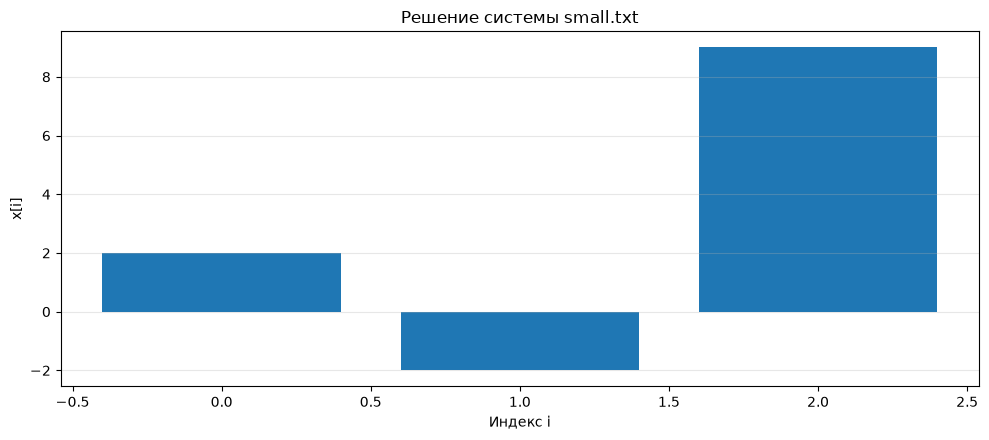

In [6]:
x_small = solve_and_plot('small.txt', small_text)
assert np.allclose(x_small, [2, -2, 9])

large.txt: N = 100
Решение x:
[ 375.  524.  671.  816.  959. 1100. 1239. 1376. 1511. 1644. 1775. 1904. 2031. 2156. 2279. 2400. 2519. 2636. 2751.
 2864. 2975. 3084. 3191. 3296. 3399. 3500. 3599. 3696. 3791. 3884. 3975. 4064. 4151. 4236. 4319. 4400. 4479. 4556.
 4631. 4704. 4775. 4844. 4911. 4976. 5039. 5100. 5159. 5216. 5271. 5324. 5375. 5424. 5471. 5516. 5559. 5600. 5639.
 5676. 5711. 5744. 5775. 5804. 5831. 5856. 5879. 5900. 5919. 5936. 5951. 5964. 5975. 5984. 5991. 5996. 5999. 6000.
 5999. 5996. 5991. 5984. 5975. 5964. 5951. 5936. 5919. 5900. 5879. 5856. 5831. 5804. 5775. 5744. 5711. 5676. 5639.
 5600. 5559. 5516. 5471. 5424.]
Невязка ||Ax-b||₂ = 6.744e-10


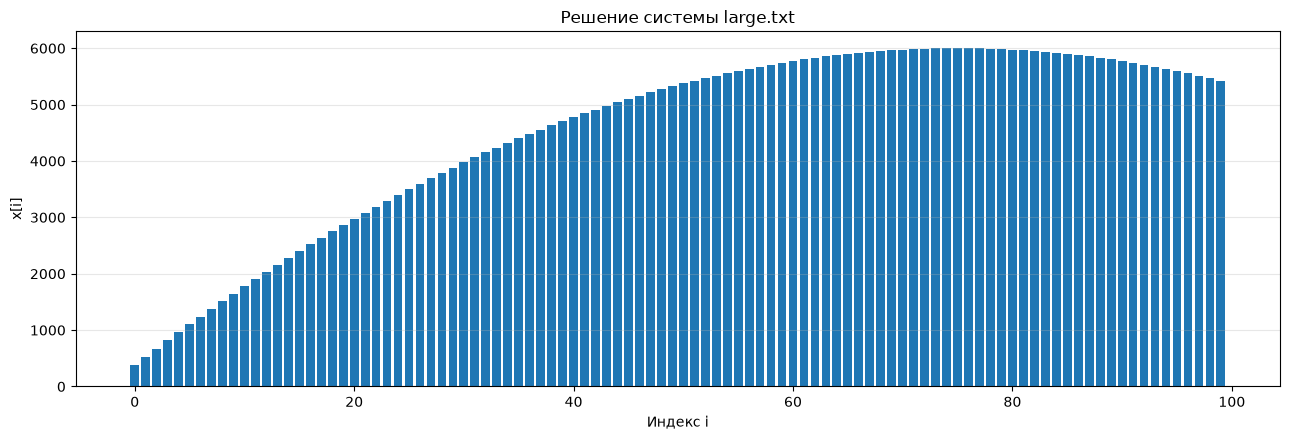

In [7]:
x_large = solve_and_plot('large.txt', large_text)

## Эпизод 3. ОДУ: символьное и численное решение

Решаем уравнение

$$\frac{dy}{dx}=-2y(x),\qquad y(0)=\sqrt2.$$

Сначала вызываем `sympy.dsolve`, затем `scipy.integrate.solve_ivp`. Сравниваем значения на отрезке $[0,10]$.

In [8]:
t = sp.symbols('t')
y = sp.Function('y')
eq = sp.Eq(sp.diff(y(t), t), -2 * y(t))
sym_solution = sp.dsolve(eq, ics={y(0): sp.sqrt(2)})

print('Символьное решение SymPy:')
display(sym_solution)

Символьное решение SymPy:


Eq(y(t), sqrt(2)*exp(-2*t))

In [9]:
exact = sp.lambdify(t, sym_solution.rhs, 'numpy')
t_grid = np.linspace(0, 10, 500)
y_sym = exact(t_grid)

sol = solve_ivp(lambda x, y: -2*y, (0, 10), [np.sqrt(2)],
                t_eval=t_grid, rtol=1e-11, atol=1e-13)
assert sol.success, sol.message
y_scipy = sol.y[0]

diff = y_sym - y_scipy
print(f'Максимальная абсолютная разность = {np.max(np.abs(diff)):.3e}')

Максимальная абсолютная разность = 2.644e-12


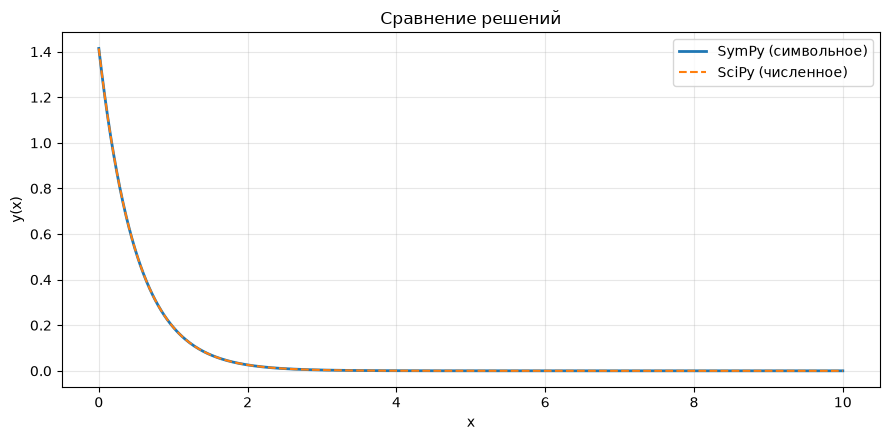

In [10]:
plt.figure(figsize=(9, 4.5))
plt.plot(t_grid, y_sym, label='SymPy (символьное)', linewidth=2)
plt.plot(t_grid, y_scipy, '--', label='SciPy (численное)', linewidth=1.5)
plt.xlabel('x')
plt.ylabel('y(x)')
plt.title('Сравнение решений')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

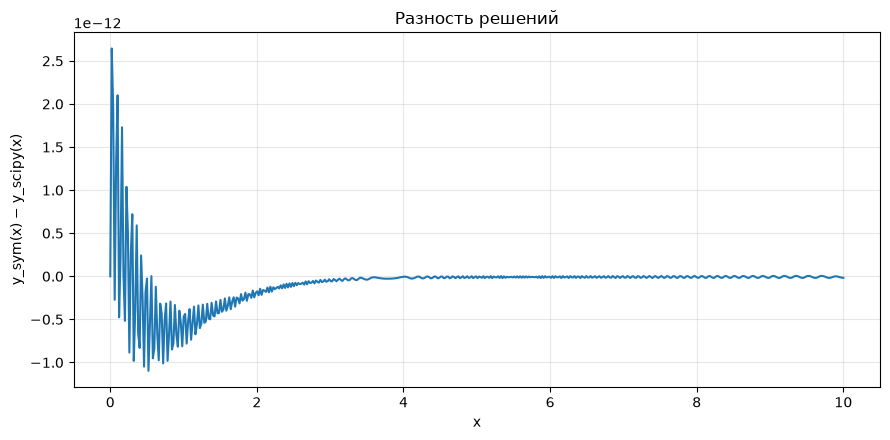

In [11]:
plt.figure(figsize=(9, 4.5))
plt.plot(t_grid, diff)
plt.xlabel('x')
plt.ylabel('y_sym(x) − y_scipy(x)')
plt.title('Разность решений')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()